<a href="https://colab.research.google.com/github/Subha12125/Pothole-Detection-System/blob/main/Pothole_Detection_Prototype.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:

!pip install -q ultralytics opencv-python matplotlib pandas


In [ ]:
#importing torch, cv2, matplotlib, pandas, YOLO
import torch
import cv2
import matplotlib.pyplot as plt
import pandas as pd
from ultralytics import YOLO

print("Environment Setup Successful!")
print("PyTorch:", torch.__version__)
print("OpenCV:", cv2.__version__)
print("GPU Available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Environment Setup Successful!
PyTorch: 2.11.0+cu130
OpenCV: 4.14.0
GPU Available: True
GPU: Tesla T4


In [ ]:
# Create our project directory
import os

PROJECT_DIR = "/content/pothole_detection"
os.makedirs(PROJECT_DIR, exist_ok=True)

# Create sub-Directory /dataseta and Results
os.makedirs(f"{PROJECT_DIR}/dataset", exist_ok=True)
os.makedirs(f"{PROJECT_DIR}/results", exist_ok=True)

print("Project directory:", PROJECT_DIR)
print("Project folders created!")

Project directory: /content/pothole_detection
Project folders created!


In [ ]:

# select the uploaded ZIP file
zip_path = zip_files[0]

# destination folder
extract_path = "/content/PotholeDataset"

# extract dataset
with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_path)

print("Dataset extracted successfully!")
print("Location:", extract_path)

Dataset extracted successfully!
Location: /content/PotholeDataset


Verify dataset configuration

In [ ]:

import os
import glob
import yaml

# Find data.yaml file
yaml_files = glob.glob(
    "/content/PotholeDataset/**/data.yaml",
    recursive=True
)
print("Configuration files found:", yaml_files)
if not yaml_files:
    raise FileNotFoundError("data.yaml not found. Check extracted folder.")
DATA_YAML = yaml_files[0]
with open(DATA_YAML, "r") as file:
    config = yaml.safe_load(file)

print("\nDataset configuration:")
print(config)
print("\nDataset YAML location:", DATA_YAML)


Configuration files found: ['/content/PotholeDataset/data.yaml']

Dataset configuration:
{'train': '../train/images', 'val': '../valid/images', 'test': '../test/images', 'nc': 1, 'names': ['Potholes'], 'roboflow': {'workspace': 'gerapothole', 'project': 'pothole-detection-yolov8', 'version': 1, 'license': 'CC BY 4.0', 'url': 'https://universe.roboflow.com/gerapothole/pothole-detection-yolov8/dataset/1'}}

Dataset YAML location: /content/PotholeDataset/data.yaml


Check images and labels

In [ ]:

from pathlib import Path

dataset_root = Path(DATA_YAML).parent
for split in ["train", "valid", "test"]:
    image_dir = dataset_root / split / "images"
    label_dir = dataset_root / split / "labels"

    images = list(image_dir.glob("*")) if image_dir.exists() else []
    labels = list(label_dir.glob("*.txt")) if label_dir.exists() else []

    print(f"\n{split.upper()}")
    print("Images:", len(images))
    print("Labels:", len(labels))



TRAIN
Images: 1245
Labels: 1245

VALID
Images: 120
Labels: 120

TEST
Images: 62
Labels: 62


Load the YOLO model

In [ ]:

from ultralytics import YOLO
# Load YOLOv8 Nano model (which is already pretrained)
model = YOLO("yolov8n.pt")
print("YOLO model loaded successfully")


YOLO model loaded successfully!


## Start training

In [ ]:

# Train YOLO on our pothole dataset

results = model.train(
    data=DATA_YAML,
    epochs=20,
    imgsz=640,
    batch=8,
    device=0,
    workers=2,
    project="/content/pothole_detection/results",
    name="pothole_training",
    patience=5,
    save=True,
    plots=True
)


Ultralytics 8.4.200 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/PotholeDataset/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=20, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=pothole_training, nbs=64, nms=None, opset=None, optimize

Locate the trained model

In [ ]:

import os

BEST_MODEL = "/content/pothole_detection/results/pothole_training/weights/best.pt"

print("Model exists:", os.path.exists(BEST_MODEL))
print("Trained model:", BEST_MODEL)


Model exists: True
Trained model: /content/pothole_detection/results/pothole_training/weights/best.pt


Load the trained model

In [ ]:

from ultralytics import YOLO
from pathlib import Path

model_files = list(
    Path("/content/pothole_detection/results").rglob("best.pt")
)
if not model_files:
    raise FileNotFoundError("Trained best.pt model not found!")

BEST_MODEL = str(model_files[0])
model = YOLO(BEST_MODEL)

print("Trained model loaded!")
print("Model path:", BEST_MODEL)


Trained model loaded!
Model path: /content/pothole_detection/results/pothole_training/weights/best.pt



image 1/1 /content/PotholeDataset/test/images/352_jpg.rf.1979b3241c0d750ce0a18220e38977b9.jpg: 640x640 4 Potholess, 12.4ms
Speed: 1.4ms preprocess, 12.4ms inference, 1.4ms postprocess per image at shape (1, 3, 640, 640)
Results saved to /content/runs/detect/predict


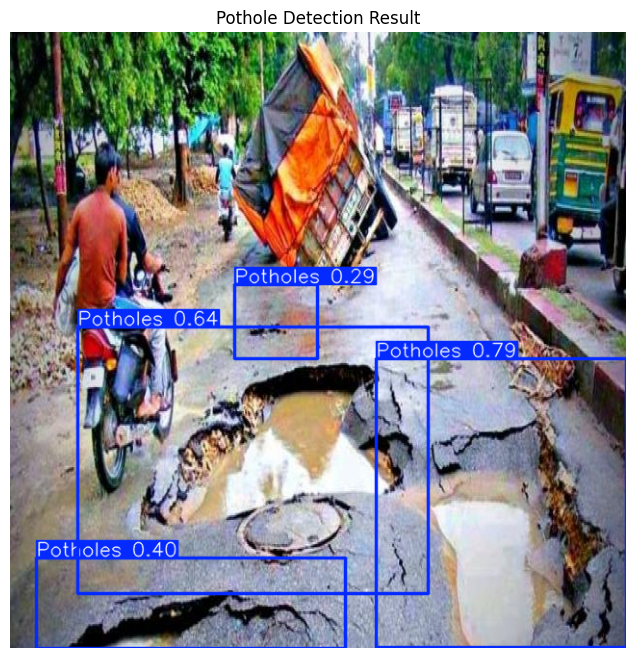

Potholes detected: 4


In [ ]:

import random
import matplotlib.pyplot as plt

# find test images
test_dir = Path(DATA_YAML).parent / "test" / "images"
test_images = [
    p for p in test_dir.iterdir()
    if p.suffix.lower() in [".jpg", ".jpeg", ".png"]
]

if not test_images:
    raise FileNotFoundError("No test images found!")

# select one image randomly from the test images
image_path = str(random.choice(test_images))

# run pothole detection model here
results = model.predict(
    source=image_path,
    conf=0.25,
    save=True
)

# display the result
annotated_image = results[0].plot()

plt.figure(figsize=(12, 8))
plt.imshow(annotated_image[:, :, ::-1])
plt.axis("off")
plt.title("Pothole Detection Result")
plt.show()

print("Potholes detected:", len(results[0].boxes))


Now testing on multiple images

In [ ]:

for image_path in test_images[:5]:
    results = model.predict(
        source=str(image_path),
        conf=0.25,
        save=True
    )
    print(
        image_path.name,
        "→ Potholes detected:",
        len(results[0].boxes)
    )


image 1/1 /content/PotholeDataset/test/images/429_jpg.rf.e1c10e0922e75bb0ba2a63ae6f3c93f2.jpg: 640x640 3 Potholess, 12.8ms
Speed: 1.4ms preprocess, 12.8ms inference, 1.5ms postprocess per image at shape (1, 3, 640, 640)
Results saved to /content/runs/detect/predict
429_jpg.rf.e1c10e0922e75bb0ba2a63ae6f3c93f2.jpg → Potholes detected: 3

image 1/1 /content/PotholeDataset/test/images/410_jpg.rf.b57fd5e3aac9902376d36fe051e82af6.jpg: 640x640 9 Potholess, 12.5ms
Speed: 1.0ms preprocess, 12.5ms inference, 1.3ms postprocess per image at shape (1, 3, 640, 640)
Results saved to /content/runs/detect/predict
410_jpg.rf.b57fd5e3aac9902376d36fe051e82af6.jpg → Potholes detected: 9

image 1/1 /content/PotholeDataset/test/images/529_jpg.rf.daefcc05267f5db0d2fe881532ac5d05.jpg: 640x640 7 Potholess, 12.4ms
Speed: 0.8ms preprocess, 12.4ms inference, 1.2ms postprocess per image at shape (1, 3, 640, 640)
Results saved to /content/runs/detect/predict
529_jpg.rf.daefcc05267f5db0d2fe881532ac5d05.jpg → Pothole

In [ ]:

from google.colab import files
files.download(BEST_MODEL)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Evaluate Precisin, Recall, mAP50, mAP50 - 95

In [ ]:
from ultralytics import YOLO

model = YOLO(BEST_MODEL)
metrics = model.val(
    data=DATA_YAML,
    split="test",
    imgsz=640,
    batch=8,
    device=0
)
print("\nMODEL EVALUATION RESULTS")
print("------------------------")
print("Precision:", metrics.box.mp)
print("------------------------")
print("Recall:", metrics.box.mr)
print("------------------------")
print("mAP50:", metrics.box.map50)
print("------------------------")
print("mAP50-95:", metrics.box.map)
print("------------------------")


Ultralytics 8.4.200 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 3,132,707 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1067.7±203.9 MB/s, size: 71.9 KB)
val: Scanning /content/PotholeDataset/test/labels... 62 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 62/62 1.5Kit/s 0.0s
val: New cache created: /content/PotholeDataset/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 8/8 2.4it/s 3.4s
                   all         62        279      0.651      0.575      0.595      0.216
Speed: 9.0ms preprocess, 12.6ms inference, 0.0ms loss, 4.2ms postprocess per image
Results saved to /content/runs/detect/val

MODEL EVALUATION RESULTS
------------------------
Precision: 0.6511311455474156
------------------------
Recall: 0.5753117723494233
------------------------
mAP50: 0.5947307883128268
------------------------
mAP50-95: 

Add pothole severity estimation

In [ ]:
#Low severity
#Medium severity
#High severity

def estimate_severity(box, image_width, image_height):
    x1, y1, x2, y2 = box

    box_width = x2 - x1
    box_height = y2 - y1

    area_ratio = (
        box_width * box_height
    ) / (image_width * image_height)

    if area_ratio < 0.02:
        return "Low"

    elif area_ratio < 0.08:
        return "Medium"

    else:
        return "High"


In [ ]:

import cv2

image = cv2.imread(image_path)
height, width = image.shape[:2]
results = model.predict(
    source=image_path,
    conf=0.25
)
for box in results[0].boxes:
    coordinates = box.xyxy[0].cpu().numpy()
    severity = estimate_severity(
        coordinates,
        width,
        height
    )
    confidence = float(box.conf[0])
    print(
        f"Pothole | Confidence: {confidence:.2f} "
        f"| Severity: {severity}"
    )


image 1/1 /content/PotholeDataset/test/images/169_jpg.rf.d1ac76c1f3c834e5624ac3aefff08a8c.jpg: 640x640 7 Potholess, 12.5ms
Speed: 1.0ms preprocess, 12.5ms inference, 1.4ms postprocess per image at shape (1, 3, 640, 640)
Pothole | Confidence: 0.57 | Severity: Medium
Pothole | Confidence: 0.56 | Severity: Low
Pothole | Confidence: 0.51 | Severity: Low
Pothole | Confidence: 0.50 | Severity: Medium
Pothole | Confidence: 0.45 | Severity: Low
Pothole | Confidence: 0.34 | Severity: Medium
Pothole | Confidence: 0.30 | Severity: Low
